# Person 3: baseline training, tuning and evaluation

This completed notebook contains the executed six-baseline experiment on the supplied 84-image SEM feature table. Saved tables and plots can be inspected without rerunning it.

## Reproduction scope

Open this notebook by itself in Google Colab and run all cells. The 84-row feature table is embedded and SHA-256 checked. A raw SEM image ZIP, GPU, PyTorch, OpenCV and scikit-image are not needed for this cached-feature reproduction. This notebook does not repeat raw-image feature extraction or CNN training.

The tested training environment used Python 3.12.14, NumPy 2.3.5, pandas 2.2.3, scikit-learn 1.8.0 and Matplotlib 3.10.8. See `requirements.txt`. New outputs are written to `person3_completed_results/` relative to the working directory.

For local execution, start Jupyter from `person3_evaluation/`. The parent repository contains filenames such as `numpy.py` and `sklearn.py` that can shadow installed packages if execution starts from the repository root.

## Evaluation design

- Training: 76 images and 28 source-material-treatment condition proxy groups.
- Fixed test: 8 images representing 4 material conditions at two magnifications.
- The groups are not verified physical specimen IDs.
- Parameters and model selection use training folds only. The fixed test was previously evaluated, so this is retrospective evaluation rather than a new blind validation.
- `CNN historical` uses the original saved predictions rounded to 3 decimals. It is a contextual comparator with a different original preprocessing protocol.

This revision updates explanatory Markdown only. The previously executed code cells, their outputs and all training predictions remain unchanged.


In [1]:
import base64, gzip, hashlib, io, json, platform, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV

try:
    display
except NameError:
    def display(value): print(value)

SEED = 42
OUTER_FOLDS, INNER_FOLDS, RF_SEARCH_ITERATIONS, N_JOBS = 5, 3, 6, 2
FEATURES = ['gray_mean', 'gray_std', 'gray_p05', 'gray_p95',
            'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation']
FEATURES += [f'lbp_{i}' for i in range(10)] + ['edge_density', 'laplacian_variance']
RESULT_DIR = Path('person3_completed_results')
RESULT_DIR.mkdir(exist_ok=True)

FEATURE_CSV_SHA256 = '3b9c36b606e2049c2451763b522a228a8102bc06fd25eadfbc0cce06cbb91cad'
TRAINING_LOGIC_SHA256 = 'a0f5555675e4f0cb205ee58bf5da8ad4afd0f5146ed7ca1e32ab65192762073d'
COMPRESSED_FEATURE_CSV = 'H4sIAAAAAAACA+19a29c2ZXd9/wKwUAAN1JTOO/HRweexAGSjAF7kI/CeXYzVlMCpTamgfnxWevsc6UiRYlkk+o2BpmB2cVSPS7vPnvttd/z6s24Lj+O0w/lpl+P9+9PP5bvr6/mVSsfrt5en96/e3P1Ac99GDdX5c3pw80oH34c1x8+PXrdfm5vxvvT+/Hj65vxPd90fNbrH8eHH972T7+/76f3b3+6aeP1+w8/9Z9P7e11v+L3vP7+5u1P707f35Sf8aZyLY/ef+jy4J3y+0HGgzftx9d454eb8v6D/PbD2x/ffj+ux9WHn+UJPL75/ufjpTc34438OW/qu9dq/dTrp1k/7frp1k+/fob1M66faf3Mp9G/H6/7uH7Pb3lT3r0p7apcv/57wZ25buP4y65wA/H3/VCMD6eJm/TTzcCNaVfvxuntu3Hd/v767+Pm/bq5f5MXH79f//Tju5+P3/7TH3Fzy5tXf/npx/LXUv/oXhklt/pVUP+Gp29maeP87vr7U1JnE05BQSjl6vokbzzxja/wzld/dCejTvsNp7/88PZmvPrjq9/3n27eQkDj5ruTOltn/emvb9/0V+PDq/Lm/Or3Rhnz3T1Pvfr3V/vK/v3VxVfgN3yJtuGcslbuZONZK+Oiw4fj+ZjwM52jyzF5POVisNpkPNI+GascXxeTCjbyDTkqq8J6b7ZBm7CeDTp6Yw0fRnyHy/IweRsyP0olE0ywTp7V+BT5hKCdD5bfFbwyNvFRDFqHzH/Hh6eQcMnG5XxOFp/kSmsz2DL0tAM/YuxuzjZ810M1X3qbLSqXVSsZ757Bm66z193p6Kw6vb25+v7qurwx6vU6tj+UN/N1gcbgTLxuN2/fqdd/1yd/5q3BBfizOZmzO4dD5v8bp/Xv4zM5R1zeZ2L+1+uliqOfHpKxsU+X8MdPx2OIEZdqU7QniBl/v41mS9fxpz7b6DPuMeVrTbLO8/5qG1OyngKKGs96bUXEOAIqLLGlLSmfrQ9hiTJS2iHufzday0uz0jE7kbC3ymgjIsZHGKPXccpeKW2WjLVROD3803MIQUPy1kR9dsnlU9Gp9mnbsNH2opw2tfuStS2hmqGjDbGVUHqZVrviamxhFuUjDpCtqdRnC/lP5l/Ml3Uaso6fyZpveViXY8YtfLKk1+WIEmt1xt/p8FX57JVTVqTsNH76c0hZLW3ykIvLPqyj5QIkzrseozEiKmdyFm3NGifHLbn6BF1069kQtbd5fXhSUFfv18OIM+CjSBiilLfhtOhoFnTgvz4bHdZDl1Nc+hxU8DnmE45fOieX8qn7akpToeI0AGy06dlMF/Tg/2bFR9RQ3fSzZO+KsqUGP3ue1sxUi9PPFvA/f/ihXL9981Xcjp/jdlT/+Xjrw7LOANKny/riKw6RZ9xCqMjJ6nNSGWdcZO6dyBxgLDcaYOz1kpRx1sUYKR6IDzonyK2CARTKQ8CBSUvqeIAjIniNc+EF8CH1QIuwHlqb9quji0ASf0exI+DEi8mIXqcgJwCQYQ3ehis1+A3g45XNceasfKERaNk4ZVL0yZaU2lA+xBH8MDENW02GZttgq69FzxHcDM+W+x9vfv4TMPPr9tp9Jne87dUPeN/DQnfhlyj48flb4kafjYkKzMras9XJio3FjaSpDhB0iDlRSt6ELXJYzAALrRfIwBA4kRHOgRerm2HTrbVerLWNammsisbptKQIMcPaKn3nfMAWKDkdOSjvlKi0TcFpJ98LW7ORJiZ8sz/hiolFQKLujC55RNrs4FtIPQ1tVa1Nq67AbGI2MNhp4vuatdPX2Isr+CerB17+bIH/4acPb9ubAov9NZGrz0X+8Y0Pyxxn/xfI/NOVidAdBAfuFEnPojVaxIN7yZ94ykEx7aJnXrsoGgaIByhTYgmHxshBgJwhss2vcgbBWp8EPFeC6B54HwSlFWSrYl4yD8kDa+RZ5wJEueSrjN+8LEGzF3zonGFJlr4bmJyk8bkmKHMmrzilAsUH9erDDNtAKWbMI/WaRhqBjDC1DltTTLfVVZDbOnCVMAYlUNPds2X+BVr+325KI+N/PC8/3vGNibkC+QbR9pR8cJBDwN/DE0FtdyDtKaXFtsC8tSi2Tgm23y3JJw2rbMWuAxhcUusVgvtLstBwaPSiABB+CsYZMeKAEbxecABKm6xYBLA40Acjn4LD7eISOhA+Lk6n8WFaywEC29fOQYE02N/Z0BJlo3Kx3aRpba+9t2bKGMlNyBmor6epOJcJJAQYP22eZXbbwAV05ffWl+Tot4T+IEl/QOAvwdIhRVhwTZpujCV11mdCZvAL2nGkTFq+D6SEV0Yr9jUYo/hssjCLhxGHPbBm22IDyS6hUl5AXSd6DJ7tRWYKJCLbDfQQmJdXgNvhfMiJwT8owfdo4cE5+W7oZlwGCB4kjhSwDhYH7BOfdgIJz7nVij+kQO1D6NE1kAKo9sww5S4VG2YvGeoOthdqVsWYooqfBn6afkGm/vO9ev5Vrv6AuJ9N1h1cMXpXgPbkwc1ErbNfvI0saYmUttSKOxZBrtRysxNv++bXCRZWnGiw4SSydwH+tsA5PDG3eZjyUD0x8WBOxoalon6Zjn1mcCBAAuVQwdkygiZ4LQ4eH4KRhczjA58CHiU4PNh60r7MaAtACm5Yr1bBzx44vs7HCA+x5lA9oH6Cqc+p/UyhdjA7b4pv8duw9btw/jBdf0DcL8XXodl+3TewXhJqfdJL7GqFWbTdwvQxe79cb+2Mg6Iu9YZFty4JBVMwrtuk41uznAZHJE/ip+PYAC2CvMLa5fkpemM4JNvmG0+Tsc6GA1rIQ1yVA9oKXYcBX8rt+SwNuVIWyg3ML3DNh+pQ1Nl9n632ACuuYd8TJG5DTi2U0TwoXrTKTl1NAH3DlSjd5zDfhq1/Zsa/TtcfEPqL8HXtIAAY2ZOL+ED4R1E0PeWl6RCCXwEz8GSVVgwGDM4kgV0om/BrTTsdN//GGdHLDFDguNN+226rhayB/1srPgD0ldZarLvJuFZh6zngBVnoGqx1dpu5qShRgxgszl1gTCEAAhgYzDPC8Wqz1BSHq7AcFtba+Kq61WHghMGug7GrStKXYq8tdVP1IEvo5lux9bsif4iuPyDzF+Lr+ewArOlk0xkMDXZW9Dy5Zcjh9GqvtyEPYcVdALzO20WyEtwrZfLtGCgsevKbjYPmx5CVhNPglZtF2SAqWCUTJBwDpc9uU3o45UELxPsILBDfLKr9PuH2y6A7x1grAN5GIJUDGMGSQ7JteBA1sPFZRwpFVdPhs5uSAefRlxBGhWfZTcSfkRSOBl6L67Fl/HK5/58frj6Mx8TR16V+krq872a8x+MnBdPpwDxW9Bdfci9vN+7siOIn60DhJFSyiZzGQ6orNdHBAAMfRe3hOfulzBGACxsu2B2J5ELB3OGj482Qo4jUw6NLIS5+B+mmtKOzcKfw6XE/hgGzWQ4J8GPRCM1T5LOggEs4Lmk5LgZMw0HhXdAQB9QhRtABDwCvRfmhodceoJF9MBGo1G0pjaHZWAY43mxKqznhuQMS8Mai53OPwJfC6hGvu1fqj42t27PJv1Did6g7wD1BqVeEHTY8+SAKH/Jy06B+bhGyEKDSfoW2YYclzJpAk6LahtjCtxaXStHwr5fyjMByCOQHhfuu7X4caSwEBvBW8evxWRauWxBiD5X0QtthS3A6+NWg+9G77fLhbOAyYATi2fIqimLUP9RI8K7gbcqoOnWcNdru80yp4WSN1BR4X/XDwbuwY1QwgVrTfLbCPxBfT7d880upPy7Kbr2Kv1DmF+zdWHyQU0u9fWbMfCt4WETOUeB8Cl+G+y7BEthBFxcSQPEMnLYN6zn7nQ0BzdZaYuxgiVkis9HZuOWNz4rKbxvv6DVs9xy/CG+HgwBVXewtHOYCDhuuYXl3xgKcGT0CpTdgomQD+BRwtGlH7qoB7H3Fz2JGdrNOKDiUfkCxm1NQ6uAbLgvIMSzdhvCciIzc3Aej7UD3+AWJPynk7r36pfB+T9w9MXUBHbMebpyGNLe+W/yE/5uDECmQAJB2cZBhnP1CeogIVGz7XM7yNTtHBg9OkjBAdPC9eEgd7v6mZfDrsoRvAdjMv0jSFEixPy97UHwjIXaQPyfunIaNWCfEMg8G2D8BF9zZwMu2zYDetwZWQbDWA8fGJCC6BqXHKfDKtEj+7lRreWhVQyh4TYwtgBI8G90fDLtD5fMXzPvjY+8J9+SXCf8On4ffHhget6B4QEZgqzC7IJFYg5u7PDgA6vaaPZQO0uJFGDhnO+IO2hb8jsOugN1nEVfIbIfifALoS1odVsMclj/CA8TRCLetBbgDGMVOvYCZr1y5NTkFnBs4cIZ+DT535lJSCBPOZzWwF12BvZfWfdF12JaGZhZGqdibraO71Aqk7wE0rtranyv2RwTfIXj3Bc1/QgTeMC3xy0R/l9brcM7kwycLAQdl9Ra+C8uXg58UVwIuaGZo4rLyFkR/ATlkmHfyCxgOvrUZOTDdCT8MCqQqi1kAssYYdhgedzR7eQkzOvusgCuGRSrADOHlhfVqBn+dxI4YlMW5EbsQcfGR8QdzxqW5k48VDD5Gr7qfHp7aGCYAHGqfuY3hp26ppDknDkmFjS+difWmG9hJZ4bh29D62/G5R/P6B5y6FyX29gwIZkkCgAAcIG1/PqR1BhQkLwAAiqyE2EPqwSiJ3FEBhQ5AT7ME7GC1yReE6YG6+SR+G8S6RQnf3cD/2xyf4d4jQROSmAMAABiHgIsmIRHkN5opVDFAMB3BARg05I6vx5dMn2bRppdYNBxHsFDIWnedR9S99WKKBSGJocK+uA7GGBxea2BLAAHOpRck9rcF/yhm/1Whvxy1h8BJcfMJTj1MZxS1xakTxDew4DvdGvdN14yXLk3POAFSXgH5wAW34a4jB39AqJkKrInQO62qd0EVqFvWXu2APVQ8btDIVm1yZ0wK24lTCji/gglAGJtxCQBrsBEC0GheDVZceaW7C44O2hjg9X04qDXQHr5jafDny0hj4t8TgGt2iLv2VNPL0/rbIn+Y1z+UcXsRYm8tbaxdxA4OOYnShXYDW1d0leVoOiextqADC7+ZFM1ZsiFQUeMOcTOgKvwNaBx2RZTLilVnSdIyjL4qccgcNNGF7dpnKLAEBXFmGN1dcqZHsbSe/5rNjh8RcYhGrAMyrOXLrsOZd76MBkFWb+vsyUDDGcxpFkJVdkxQu2FMh3WvCvw+4pCAFkTA2Deh9ncR/pHc/qGw3UuSe0feviDen5muXpzdn3RUUlSDG5wWRHsHsywhFpwG59xS6kTKbBcRgDcHyJUMuWIEXSLycJgZrt1xW2+C0AYFvue3lx8YAhaTb0Hfd+wGD3PemTelpEoD3rzdqYCUfGZlhQZNoAFiUUipOXf4itD/qX1lMVWhNcc3WXC+CVuSDTyGlsADy/AgjDP5xPOGC/wW3P6u3j+G3D8g/hdj9/Df6Eyt/AzYekhm6f9HsI8upCgIsGz/MrfeM3fNy6CZj6KvGtw7pW3eo8lmB+48Sxl3oY2mLY9b8iYlkTf8/ZD2eQgh7s/Ay4Pb1TzJk2ou2UNIO6gDoskaLVyr9qSY6dRjrUB4BQcvtJVRBKUr8DqMhW8J9y0NeABNV9a/jtR0xtcZYMbQseBcfiOKf1f+j+L4D2XfX47kQ/shZsfELCgzSPHOzOrl2UMz8yqtcGZVOiywt8G6xb7hjwe9K+AgQwh3R93Bo8JOu4GwuShYj6MSBBAyUMRJ0USi4m08AAofSXzPoo2l+t4xjSOVsgwTLePDzCGQH2wYPP0cedyapStf8+gdeh1yhaC9G/gL8H8uQd9LBOp7uI21pgo7UxmUSrG4UoA0v1z8f/6ff3hU3D6CLn+SPd71tHh9fLzS84rurXs35+zJZOHOw892zl4UVvnlN4UVYIVmKBeNVK+Coeel5VBwd2TSY4Is9kNa5c3WwQ+B2VIq6cnGd+UUIAvCXw9zZvnlHY8eLARkT6I3iul+YRvAhk0oQQtzpCMAXbcM3epTKLpFXJMtoQHiJ+xGqzgLI6Ue+yx5VoC/njjjvtsWlG+2D62KqmN0454n8esvVr+r20J+fOm7faqE73J3B6BmdhO0zjucdCsO+6qVJNTnsCQeQeLD0kkLZ94vDpfSKlIVqIY53455dBCyHBMHQfu4Q3Cg78bqXUwDJZKUKvOz3u2qCyZbJLyb8U4p2wIuHDXWGp+ckoTznWGKEBwOrOJM9/8UWHgFDpiYIgBnt6DuscMuqEyM7wV6PQJJSGHG1+vRQfF8SlN156Z5nmy/HpRPBMHbMn5cMP4JuVaR72UIHrJlVRFD8NDbXXsOE663Iw4vfRlaMFk4RlpuNkSzci7QyywRU2gXHB27C9aoa4LTQF7rBJ2TWZxP3HY4zssvWCoIn1tK5xKkscsyM+yoZGXA+onsS3E1rtGJvjuzMq94QKJJZlnA0V1zFSgP8g1u1wuwwpSCM1DB2jNYu5rw2HSHvx4GoQiIDaEzjlyfJ9uHI/BsALot3idF3oFMT5PyPZTcMGe62pOgADndQmloafTLTDKEAaSmdtIthtQkn+4ZHRVR6sW6JIXCsuhtlQ0bnLYBhheVBMgzY/JmSy3CdkvuhUZSql0B4y5KNAbChr5JtQaOGT5ZQJ+9S4pChtxB2MKplRGqgocd6qQfD7sxHdj5ABsrkHDUsNSxu9h6V3lOW3pKo6UR4LAbQNi3sMt34y8PGOaHquOeb5k1tXp1pOH0weWF8BcPi1pS6NAovRKlwHUtaTWoMaS/hBHBuPPRewRg3U0OJulsjkhb3sFxlsNtMAB2Q0mFhwPCwfV2x0v++OIMzDnKJoPO0UiMD8oPJ00isKvxTYOJOX92OZ5GH12HAhgOBk62t7AnbVTbIPWCw1yq6lGNmUcqjmGkrqDtvubUU9dGvZhZvlv9+BW7/FCw5ZmGWdsVXXEnD6VljWkQjc5ins85ZcmDQHRAZImeUBsF5mP2wOrdgoTbrTe/yuDcacfVAJ16dyaZpKTSBeBqwjbS0eFFYt3h6Vkx4yRPOC5Lug6sXVLxzK4lIw4XLCqs7Anemj2vUota42h0FHzs1bs+MiRdfFJAbloRmHwFnt2rcdUlyN8423vPZA+1mhc3zHcLor5kmR+KqDzHNMNbhkWG8bSsBWZFohQyp7icqMi/Xa+wjd+IGV0yUoACUgaqs6uYEhvPRHctqxMEdC/rIdjxkI9IW2Q9w9ZT3GbWrYiAAfX7DLkjIBvowcthCKDVYh9A+bJbPh/MBPsezak3XBq0X3XTe1w6W62zVTe4Tx7gYgar351vcJrnyHGGNqyeYGGM5/ZvYJzvetAPWOeHwPr55hluVGAg4uSB2jbC9aEeG20Fq1kBuhAa0OcAtTvtCQkuDwhSNkEqWGFXg97tKdRLsfQ+WtYS79h4sl7ioJoV6tKUkuGAS3k6K5RBtQ4qBhnbXcIKYiVV6wFc3mspfYsu8NgZXivj+MGo1NVMuljHtoMcijcsYh8xhs4CSHhUvpTp9fQJSl2HabjkBjewjf6MmMmf//mv//3COusvsTG49/ZSpfG2W9ZZf52OQTBP0Gxe013rjC/I6Wwic9r0q4BkeXeaSvW6h55KkXFwB4fWAEgQoJUFhy8VgxQxgH5JfBWAYACWuygd9oERdAH1FQsVgsXUlbBw6GuUopsI3fWi3ImJMUmCO3I/ybbCJMRdQ6+Z8cQLgBQgkgbXoCfZdXHRFmvL7DUUVyagv0GfcUZnWdW2GvczlUndjjV3WOXh6gBLf6a8F2h+WdRwU9MdUS/41g/2l5qnynjDtwgXEmQloklny9xk2gFwa8S10iYKyYYlZIEi/zCq6JIY4yC7yCEaBqh2OaJZmibeLXDA2l3GEthlLjlMr3cbOuSfbbS7q9QpnXaTscEp0qLEsCFRMNsBtMMujTYeYMxqNsbp8QETQgYoVxAruMwKtCqNyNK1lGfmyaoTP9K0nawb5JuNKL6BfNk4u03PlO+DvhVE7O6K+EnOVXqypD+D7+xwOxlRtKtpNBxVDeJdJQhCev8DFFfrI+lAKr2oNjD0KDxPcK/Czk1nqOgR9dZrtoRUKoEPSdSUITJxkwkOhz3Hpx1ZEphPvRuNVpZNwp/McosHCOtM0wy+kXniAd6t1BEHSJX3vQeAtdW9J2dKLA0/QM2VUt3lBunbQocPNNxVC0bR3XTfBrxvWetHoPdXzfWLwDe7CnOEzBnkVqw/i5ugLe8KWg/2ujo/AssKvKQdPJxiv1gwA0wp74gJe9H8DpNw+IM0mmXAszhdLEjepJtTJiTEylLUHHcN3EWxI5DahF0OHY5WFZbA75IWfC6eszQ1EUwD9M67CYM+WPeWmqNDpn2rOivfjMrDTfDBUXSvPfgGb6ungeNVKqyQK+Y54wK+AOC3xf0VBH+o5egZEE74Yw9BXPXIMLHR7Dy2NBoBOvNqMACTpoDFeSbOOukRd2H3hEVKPe6ukm20GTDPO2J2kebQQQrOth8djqDaZZ6Ltc5WsiZk51pJ4NOyGEbSqI4nAMfRG94ChUew2Wm6AvOf2WYOAz4T/KimCtS9hTwMQLu3Bo/D+qKKrq41E3JxsOBFfQsEvyvjhyD8ofTl8zGc8RLIjKFuuFx+JQlE4nFJHL6zW9XmHpRLUkaQAJxWKUzEXTXbTtNJ1nrP8bBMPN5xuQDlgU0niz8TPZxwK5C6YHa8PINPSwKELYDSnqaBGVBOAX+2Oqg92wcsn2kMx0vVuO44OVqoBUg4uDpJMSYgJAP1a8mqhopL9CNOmvBSeweCwIrHbjw8tmdxsj+AdioCJuV99bc3n8dC3dlfyHq9/mlZK+0eL2y5nPvCYy4AweEpM1HNzMOe15QpbboyrC9knAboC8GKu6TZP77SHS4uj3XXGukoYa7E87CDJvCk4y4p/9RVBONvnNqKT5a3Y+VgecHu4GmGMgsts2w+9butyGvpNIHpZr8yPC5mNtakoDnTULk52G6QarhbVtfsXPWgfkOx4ajUohgYq8pXPQ3TbwVvKsWHUdKzxf2l/hK85DNRPzZ3pc82P13Od6JkzE5SP1bYmyV9t4ZyQbHskgW8aHf4xNDpKAUBkQHM3SzAyGMSBxvS1NIwHBiytLsGOTk44dLwywExorwsOMnSWUCLwXEg26LHJLQebAw6LyCuOewjrBrzHVvFF9l14acGrxoWhYOH2I0KFAB/KC4UozPcKDPUGvdgxmi5Rwtoz4PFpyBw7C8bz5bxA10l94n6kSks/XQxX4TKFAy1Yo/OmrwGLqXiRSdJ4JQzJb3cPsF0WskZOgcwXaETZ8whQxjO1R8iYtYA2LDrBpni3+0BhgEO0WWwOet2+7/2R19JYm/ZVuVk0pGZhEMmBCwx7RklgBZZc4wv8mtS0CnH3kAcCyVZQ4MRKp1TvWZk7RHc9a5q60WX0p2uDc705DwXKHmrcNLUs4X8cCbrPjk/rYvEPl3cnxtrA/QG7EqNibZb5MmKqeb8vTWMLdHvkcQEmz0kPppIklPcQzqgHrs5iDbT794BUOftWikWkWzzC2XOu1sggqfH/T5lVvHAirVwOJ+RElaYWImq4rBtV88keA4w4bhUjhizMCax5zZTZYUw3tlTtgZUDa6+riUxghe7n9bomlJPZvoK1wxnhGOpYMZnfLbMH24fcZdTHrbMH984EuPTBX63ZYSjWwjKoGYJt87sZrHd9Q9iJqN1XOI4FSHjLCuUakIeBmcO3zhbgXGAuxJEZymPzIVQRIOdxWSPAT5gh1K9gs0VJ40kLR8jGpXdoTUw+iBjFWGnEyvJVkwnrwpVHEwwCuYzc4256Vz6rCD+M3I8iI0dtNxUNU2BQtde4ixejah65nS54l1wsEBZz/ZsabNY629f7Bp59Xv9ncjcXxaQb5k/oWdEp6cL/W4dmTGrD8TTBaPBPEazRWkRM0xRivWGTon7C72BkV9junBgwo6eQF1AvkVBDWsaJCfJ4g61RzI6GP0oJDzRCOyGAC8FRHDdFIBAPgEmWTiZTezwF3oWfFDLyyOEpNUn5Fn/nKE5uKIOp4zJ6hgnvCzdguWhs6lk1xknD3i251pHgW8XYoUhUNPWUmKLL8nOzJ3Mx0ME7YFIykswNMvktD05T1LN8OaKo+D2yWRNFn4vyOX5l2oEvcpJZJALJ7lJ4iOwkkyqwQmPZhcgRBKso3E7Wm/snrWDc7DLUVguIoFSfEPY1SgK4l5Un7Gx6PTh7u2yUTj/YQ1jw1vhK8A/iOBgTJSCNcAyD19rDGOGri002XYQ+FldGro0PUbKM3mO7jHOhxY7U24vT9AelvVjU5nPo2g2cRoT0JOTChk2upjZAmSH4PzSKM9JjMLCWeotDlECx9qRzbwb61dua03mkrj4mvoiAoQvlvWGbP9xtCaMb9q1xJAlA/IfB/itYVxiMGgEJJt5NBTD4FuGbU4cvMgpcO5UaogFuOKhq3kU5YHkOI415D7gb6kCx6qEDlyvvgErcGgg9aYDYH3gJH0bivawpJ/YDfAiJA33zIGi2TMb4/Keu5bF92JmUcqAca+TjEsmJYeXugrB4d+4o44TBCzs5LOiRyVix32F1RTinlnVuQezfBzX5o/0qILkYL3t0f8J4JfvY65LqB3eY9bAvbyMCitU10Rk6Ki1KsCtnr5NNu8XNR2cMaY/QCNhDHrzieNzqx/ddZD3YuGrcSojmecLsrOvyPvr/Oyh9PULEDTIOIVMWYNOsbFHNFya+Tk3bxEm5vOpxUe0S1QyQVnSHpQHrQce2F1/ADAOu1PT6d25tWZlS/Hwpf7SLuPS9oTkT+468y1htxHjFOSdS1WsU1pVboGjRDxdbZ9XcvyUZ+AnmcHCT90akDxXcG9Ti4XtnwrYk5Q2Nc7kZJBLgPI3vCtPuO4vwtEeLPt/kKA9IPWXYGjg5cpCHrTe3nNk3m72SMLQAJ5Lb6FnbJHZ5tZIHJUDT+Iu3mdB1xFIgRMepGqBk6u1EDCWjKpd9UDbHXd1C2sCNxykJHwfBwcXIHJmYiXu2DrBeEXLTZQeZEYBzqvcjTMbhsvwFtVoHHftqyrNZjhbEFrLPEKtgpO45n1RLbc0J8fz4FJK9s8Irvzp6t37L3dxqksZ/+l//PkvTyFn6fHz1vjRn1MzZZk/AEOGVoMH7wKzsFDc4Bnw6DWBJ9JnVZKHNADdJQWoqTkmKhitpMiPgs726MK12mxKDcDwUiimObJ4j8ZOrEzbJh7wLEkU8Pw1M0D0OR7j7fcICVatGnZx5hPnQrGpI5w6eNvwuZUZmPD0c/qQG+fsgWxAhN5G1fg0hA0Wx2l9WpVRQSzbNM/B8CXdywTXpYxFxPrSVi8RPzK79YQCwi3ei+wWp68w8Mja0BV2vCgNxd9Bca0QFoE3SFDTrzKRNfSak8yltgR8S0kLPSe4QN+lAxPC3zE3MCKWjG5ajnOyR2FfhF3gCelst80GK98RFo7biCJdYPiBAxmitcxp0eQoDUvhtJs925qUHwMU2zL8aezg7BXb4EVB8mEE1WszrFYCX1tzOAyuHa/pz5TuI+gYB/7dkfFT2BhV7ami/pyLQZlXMT3ADm41MXJ7WutGsgYchFmGpLDFzuVwNFQEI0EzkGhxcSFIp+32k+CV7arv8KlVk4Z5jedYpI5d22YTcU5uCbs1Cx9it6YHb2WIn3Y+7UZeSJyncE8A4eDzxLifW5URJ4Dz7M14F0pVDYak2pHHbD3YUuBa4FG2kKGF6ptaGYaps5QOtR5zhPhykH0rVPZ1xP56vuPZgM3lFCbu2ZhKpmAdKa3IEVrLEnLgtFN75uxqj3MyMg8cTe+chctue1EfWzE4Ph4gvJPaliNXhXcxlLFp9qdK4gDBfAR9BYYnvjSsrZO+LqgiA5lS7+3YmX/ivJ0z619OKZY4h7KQpukq+gnz33LuxpaaqppwriZkbfNsk7PadYRB9iRpE36WbS+N2LdE/GXEfrFWrHsAO61pJAyFgafYo9p7hcIYHQPsrXJgSAI8SmZYJDZAS5SEQ+T1XitgJYpCHr6XiHha33zMPuNmi52VZJ/e9qw59kAyK1xcoPMeuPVx1YXmJovd1QN5gq3twgQoMRNZKzfNQrjpRwOxxvHBN7Lat/uWSzStApzcnLOrUOtUoa1qhNK81qOCdfXO7oPxLfD6lnwfhuuvyfll0Nq4VW9rqMnem2gvivvBqxmPduI7c6SIUK/MXQZLlQG9Rz1n/ljZx9UgO21pjY472QwJRumjYwiana17CBbZQbwTFMusP/Vpt2yzR99cbiBRa68C/jZOzQj27DwXQUF6E+5wsL2AcsF9Xm57NanppuPoKtUKILc9p26GJonPbP9oediQx7eYV4+TfO/Aejz/jzCx3tpzyORkliUKkWEus6v/pXzUJ1CnJajACZRSTwiSzdlHC8rTmi0jC4bcMfGYPraYXhCuyFm1UmhiWdq/D0CSiPqFu8VGLLUbCBiTsR87eEm/RfF5XLI4dyqwBoJ22rJrzJ4sTK5trY84G3z34Ph7bKXVMGepxfTsBpypVhxbSjo7CvBv8MHAwFkX/ULj6j+X+ZpX/5nIf+WB9fkcF5mBxBmfhuIsWI/HWqkkkU3PxKQkjcGZOJNkFRQ77gY59kAptVvuYL/3NFNnLSdqxT34SuWjPoEO+bbvIR8FShdjkTNzIDIOi92AJkqQDAdF2L4B1yBlO3FZGYsd3Qkk2xYw7m4hwF7UUG5wyCqgAFa8JK6YSbm0xt5uGAHNbTlRTRxlBccrvPSw+nsFHj8X+K82rp5zLp1eJjxExdICI06XWTacca9lrXmX0+pyNn5NgPdS8m/UMafqmIMEUeMVewieswrk+Rh+SA2XyoTgdtgDqs7SwLinZBm9BySztEhGIcN+KLfLS1M8IqaaUADPgSON4SaAEpw42T4XwHOrw4IKVPyv+Y5ngBbNsiA4TJD6sNKplZPyJmyRUXU07rZ52Zn1P38R0+M9mP7bjK2HHc/sgecQc6DwamfNK1SWt6pzhd/m5xxjuV0nt+dYsXBlt1VejEmgo7ZLigQKjiS23jAdpMFaWD2s9x565rjrYH+C8maXqLB4we7eD2NkXgKuBcgBgMCF5jPzF1oNgHet8LiDKt4yGVc4wYstP5kl59bO6fTkfI8ONjmT6SUPD5Je9HOiKV+aW3+/OXefi/7XnlzPLSSsBF4JbPrGtOMsU9HLIeOAK5l2FVbaYaUmAbVcNbVcbsYr9ghD8AAwK3snLc1atSh5D0gsyuhb7hxhInJPTPBHnwgrH0T7ofKsUl1qbljoJFEWTsiTYwPMBlYZTjHnzDZWJiVQw4LrBLHkohrtFJB+5sa8Vy5qRriMrvjYXY3ZlzarLThmvQ7Hg/UthtffK3d1j9x//fH1zBZmD2Xi6kCosRbJGyUpT2iikcqBwDLtJVezNkdtX9w7ddQZwXHanBygaw+s/zjjMHwak8TubEZdd9obQhKstzhoJpvbuyfpr+11B5A2O0alrJjJNiCOhoXiscR3jAJfu0PapqoOAlgzaw1b5uYq6H2unItd4gjVxVlH50oi24aBd9CIcy8/5/Ie074GXX4S/D/GpEsra980x6DlVRFqjDSJOBlynLQ07zqG3vaeCsdJRlqKjEHYpXZ0nQjhdKxDF0YP348s/Bh05LLaiy4Y/1ZHPy9O0seKRo5Nk/BcSjIxTbNGWB/x9KAFC0A2uNaCo5A0m0TsCV5fS6XCkK8Bad4N/AI/s/buh+1Wd5D5Gavilp2ZcUiqMhVMvvXuGNB/mUGX90ieky7vF/xvMOpSs6gv0O3J7MBn6FSnj3srtOM4W1k0x7VEJu/BdtkayaUwL3mUhwfuv9hiVNw7t7cVcG6u2kPPOIB8u+8pZnsMWEjmKFeNH+euUPcZ69vee9TiAYD/6z0B1QLoue7kBELO0axcKRmNi3WCJQAYKg5IheteOFXVE/MDjyKr1cD0R+txwCyAbcLfh19aulYvO/PyHumn2377bzb10iQOtYUx57CNiNsFJReXPcg8Bgvdk/nhmfshJIhiIUyB48BpRWbHbNjUu8Mw8J/c7hm63CsYOSVv73jmxqm9hAw6rnaiLmbGeLdvGJN0714MPjvWh1Ls1gJEQBP1ecV3o+4hNpwRtybfttLhZIxJT6LH3GIpvbimgu218bJXQ0yBf0lnUI2XH2h/L97HL8n9t5x7GUSmq041cJdbWocgWyH53Cmz8NpxT1i0UpjsOQInC+ATXHcmDECftsfHXsLgdxsRxyJs06/Cbue+4PGc1oKz4e52/uITtARy2EgSd/UbNw0HL30lWvZOM7zAGO4p1dBbLbWN3GefCo5dS2AC7EuEznOsvjOtFU60Z3V6nHhQ+6gG0Mb80EvPvrxX//OX7P5vMf3Sc8cgdwmC93FYXd6MfxU94QA4jhFfVU80vDuUaqBpbg/d4e6Bw7WHwDZd55aYXbMKeabbXUeQajJ7tsPlzMRPQ3kujgRr0Y+2MS5DXE9ypRh7UEAS2UKRwVMyzUlRzU/XVegjcdlhLaPDMwAgse1blenh+cfSckqM70xtSgIViMV9g8GX9wrffQkEfqvRl/hD4JOZk3NnTjJmV95y87VsGD5zdsqSCcfHRmlCYK+n2VXLjhUUuxYd9sD7YzoHM/HH0FNHxr4TNCbtcirWMx1LZeVw7P3inOm0ayZdklXUmvxPidGQ5sE1uc9yDrZ1J864PnOtycnV2UJI07aWodoKr0g4AxWf3seIdgxcZIHvH1vQCexfteQ5p8nVMvPIL98P/vkxkIbwT8fgN+oIN0t6a95W4C4y7qmTaO5aYRRYq5xkoNZaJS7VD1wDroMMcTF7sBZ3/tq920bFXeXqMmuL98QefIvLu+Am6o8zzVmQc0QDGMF14XZBlQ6cpCixXB4cGSmg2YtmmVwHs1zNMSf2Ndjhe9MdcDFY1gYTMDjqw8VYucViNl85a9HWqZgB9i0ahppZFdVftCX8HomvnvA7Ev81msJxofDT1KL3nFBJpFz4HncpMxs9l0GGW653eYPmJHkh7FxZsadvQERK62Mwk99xWRmRt4dq4VMpMDEBQGsplooc3KEOXwBQkM2dUhzahSBxADCPtQZnby9g9ykb45hNgsqXYfooZcJ37IVTrdna2OHaK+trsTEWtiknVW2qXGfAhbnwFZvRbeoa9Es3ht8rafeZpH/91nCzCDrwcO2Q5gbhnaeR/qPlN61JeontR7LvN1iXZfknzwkrLkSQXBG56xgZA5J4jg/Jpb1VmKV2bo/jCuw325N58L1yAi72V+TAoqxdtO6kiAriDzsSyOUT3IEcGXXmlPsJnsaNSYbDq2OC22b8GDp3X6YOvfiuup3w3ycOGcwPd8gH1l8YHANT80v1otxjzFm0fiHo36IXhU7cytDg1HFr7Pbdd7ewXX6259rYvaQiEXxXRRzjL3uvbLAymY1wDPntiDv8Zxnzoxio2T1o/K+Pd+ZssQvVHDV1FnCS98xq+Pm7PQGnSUyGIa8TkoFbHbk0D37ZaPQntG+KEXjuiy65uAKvrnrL4thmB/vUeyt++YMpzcxlFsm18aISNv94Mra4WEiUFcuGXTzuiMx6KWu1HAGR1njyxDXQQqi4oU+GODGCugMq7DA8CtHZUi9lNX6tKdrzAJRXx+4YAr7sG2cVhdllNZxsvuleEmVdRTNJ/AGuKiLbXn1lZGW4BnoLLKT3J5yTOc20JrhS2bg8oL9A7mkrN0g61zgyvRQo75g4J2VOBz8eAD8G5yi+cMfRY3X61+k58jD1gSs4OPiWSRWzMXv54oBDNojKABfrQ9hzsODk7FUkHAmwV8ldYDZUby8WAadyu1AZ5Gqv/qRGQ7t3PQ1JXDr2C5q8VfpT/7gX9JZ+BAbmZT7myu8xAm8CxzKf9HSpV0hXNz08TG9MbBQNhTjtZq6hus63mdSajd2F2lNuanRQFdr+F+84eqykf4ueI1azcprkCsGsahUB8dVslplvsUlaEkCGZPahtntZMECTsfB4h0yzY9RJX7iXyQ17rg9HUm9/K3FxwZ4DofMe+EAOqLfU8SUyx5qHaU/fgpkGZq/CKVZKKGaJwDAWkkRcKLTasnOtAJ25AL76FiB6oHcGM5+RZa3VhxLDhH+may815eHAQYx6+bbwe6UeP5f6r9t5ZB13fLNYCtTMOs433dwsLT2Ha6uWGrMdMMucLa6SdXtGvU4w+ztBclEsxa1dVt9dJwSnKag9FmD3F+50ittLK7glTpZJMWwj0r/YUxYcl5iKnnPEgNbcjKQ4ieS09sHC1Z6tK6A07PeoEUS7cChqWl0WIAk2llKbt6NXriNIuivig3qBQQCPC7r4W/mW36jxyHoWx4BnsR6W4zD9wdWMcLUA6M2r4wzCEVrsGRuzMtjF2L2mHapqndmdRR/7hthTyvVSR1VzSvtYxGPTIOCBZZl7SCO4cvZ3tlJq2VwrhM3vhDynNikWAmiciDV/9ZQrTEPsLYzuXeuQeVGu+Twj9DqVsnbLmm4VmxV6JfDn0npp+CQA/TMI23jfX797U14br/7t/H/fwdvipjMQDAh3vP9w+ue//PGfOK/29+/evvn5DWR61V6VdtVf/ZdXrdzUt9evKp7923dgcO/fjXY1rxaH+wJ3g3fz51Jurv7pf719c11uLmXtvvvKP0Hij72QxfY+XorwvRUdAng74fR6l1IaLS1q4WhR47CH3eZtOPNDqq5Y+hh2cp2LTPIdGhC4I34vKiGv/zjTPoW4M7cM3UqMHjzhIiIbQ9jn0vPQHKWUdsf8pfsFooLSc+m1ObnGaQjT1A63I1UH88WVw1EXGImGgx71IAx5xmy1HmaYGfEjg22WZw314kEp9f2ng0K/13w6KL+jgP7wX//y6vel3fz85u311YebqzfjVf3pQ+lX43q8ev/h5xv+96PArmGyP/xUx/vTq6vrOW5uRv/ud485SMTKrx2k3z14kp5/oZ+fs9+tZD8AGr6/WwszNAi8sRc7Fvwa0rfCf4HZdbf71qJbLCOB0ZtjCAkL5/agKNDQPZWZzRppz7NwPn9cV+yc3g2zn1KBipmco6z3o0uK15m0qQd8RYkWc3OWY7cHs0kQK/crBMAQExG1OFdCnBxD4Tlvjv4mqwjSYCWnzhV0NPjRQzLcfRdj4+l73kn78O6nTyeNQB9uQ9Jf//yvr37/4Ydx8+NboNd7ggFxAQaHRHD8MnSCCj8HnZ54TfcB1Yoas93JxRWS5RY6fcFcWcUpuUPiid07DTkgOEu/PNul7e2gkGJB196vEkhz9I5B0B3Zm2+59PDozuKWpF0BDFYS8g4yKW2t9Avh3OHs3akbMIZ71UKG7besWc4noN90MzRdTJ86mIqvoQtT8aWpVjcAWbYEktqgcHhKGyX4nCbOem7PqRbhAXp7/fO/XWCVY2PVrRP0L3iBGJPy41Vf0vnh7bt3kMSW0o9X+I55VcfN++8eB0rgFc85P0+6ovtOD3euwdk3a8cqu7DcSbzdfIwzDFL8x+6LHI7TE7WSijOIM2zuE10Ix4nAIdhzRblEOe0Z/6xNybKdRbOnYLdxaQ7RUcfWVbu7Bj7t9dGcpiHpS21BvGUUG6uMQQkNB7nFteWzmzY8LJrunm+GIdMFnKm12K2JPeOn1aG1aj3LTSowsmicpzlbssM9nxAx4X7JiPj7fyRKFEiJpBTZcoy/rBpYPQcBRowxq7XIi1MOdvYhealD54SenT9makrGbuH+sFBkmxNAwd7Ox3Hlye+CRBfV5tzsAvk4mdxuo8fdX8dseg7o2EsHEidkroNkWRQDGu6SZ2vRCeeVAQ5OKTYVBLxzhlOLcIWqtY0RbjtZmVYteFdqw+BqyoRJG4xzt/p8OvTpmAgf+nRM/j8h+p3MX+RYzTU+gLMS5Jwpt9cP6Sw5ascdL3rPZYKeLza0cl/SMyrDj8M+aPZY6opzE3f8DScjpTuZUTzEkd1zJC7GhzA0a3cz6prndHvvMzdQRc7/snBB1wCLky41KThaw2qnmy/ZhhJtN5yf7CNHTU3O2k8D1gwEbOCZWlSPhQF1Lk15Nhv6dNCEDt3Go/+gfMgkzuZ0a8J65qJnGSkjrVEQjePiv2V5qetpR9ZTkJ1WHKh7LH7V3Hm0HTf+/7EMXMEd09uD55T2I6qPN+5hjiywt9vFP0bxX6wi1Z4LF2SuSfTrQ1YboJaB7tyEyD159jRmmkC/msCeuwP+JT8azFwfVoE30xp23QFdgEPDnvfiBnhUBmkydDZfgA9dgNUiRLfP0H9ARmTZoMd9NY6DaNjlunto90ody03iq/gayADGs9ssuAl6N1EqidhyqKe1uw5nDRvdLVSwcsdKvMzS/T2zGbCm9QYrHJ+d1WWy0O91WpwwKXO+4RNat7M+ni1esmXRG23WSoHsGSTFcUzgNp0jkeJsJrdmgCxjughWHaIuo845iuZoDB6zBk4UWlGGC+lV6n7+8hP0/wDU4awqKacAAA=='

raw_csv = gzip.decompress(base64.b64decode(COMPRESSED_FEATURE_CSV))
assert hashlib.sha256(raw_csv).hexdigest() == FEATURE_CSV_SHA256, 'Embedded input checksum failed.'
data = pd.read_csv(io.BytesIO(raw_csv))
assert len(data) == 84 and data['filename'].is_unique
assert data['split'].value_counts().to_dict() == {'train': 76, 'test': 8}
assert np.isfinite(data[FEATURES + ['hardness', 'magnification']].to_numpy(dtype=float)).all()
assert data['source_image_sha256'].str.fullmatch('[0-9a-f]{64}').all()
assert data['source_image_sha256'].is_unique
train = data[data['split'].eq('train')].reset_index(drop=True)
test = data[data['split'].eq('test')].reset_index(drop=True)
assert train['condition_group'].nunique() == 28
for column in ['filename', 'condition_group', 'source_image_sha256']:
    assert not set(train[column]) & set(test[column]), column
X_train = train[FEATURES + ['magnification']].copy()
X_test = test[FEATURES + ['magnification']].copy()
X_train[FEATURES] = X_train[FEATURES].astype(np.float32)
X_test[FEATURES] = X_test[FEATURES].astype(np.float32)
y_train = train['hardness'].to_numpy(dtype=float)
groups_train = train['condition_group'].to_numpy()
print('Verified real input: 84 images; 76 train / 8 test; 28 training condition groups.')
print('Input SHA-256:', FEATURE_CSV_SHA256)
print('Training hardness range:', y_train.min(), 'to', y_train.max(), 'Shore D')
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| scikit-learn:', sklearn.__version__)


Verified real input: 84 images; 76 train / 8 test; 28 training condition groups.
Input SHA-256: 3b9c36b606e2049c2451763b522a228a8102bc06fd25eadfbc0cce06cbb91cad
Training hardness range: 67.32 to 80.76 Shore D
Python: 3.12.14 | NumPy: 2.3.5 | scikit-learn: 1.8.0


## 1. Prespecified baseline training and validation

The functions below retain the previously specified training procedure. Six strategies include a training-mean predictor, ordinary linear regression, fixed and tuned Ridge, and baseline and tuned random forest.

Nested condition-grouped CV uses 5 outer folds and 3 inner folds. The random-forest search evaluates 6 candidates. Scaling, magnification encoding and parameter selection fit within training folds only. Model-family selection minimizes image-weighted outer-CV MAE.

Magnification uses a categorical one-hot encoding. Training contains 60× and 500×, while the fixed test contains the unseen 250× and 1000× categories. The encoder maps both unseen categories to the same all-zero magnification code. The current experiment retains this limitation rather than changing its protocol after viewing test results.


In [2]:
MODEL_NAMES = ['Training mean', 'Linear regression', 'Ridge fixed', 'RF baseline', 'Ridge tuned', 'RF tuned']

def score(y, prediction):
    y, prediction = np.asarray(y, dtype=float), np.asarray(prediction, dtype=float)
    denominator = np.sum((y-y.mean())**2)
    return {'MAE': float(np.mean(np.abs(prediction-y))),
            'RMSE': float(np.sqrt(np.mean((prediction-y)**2))),
            'R2': float(1-np.sum((prediction-y)**2)/denominator) if denominator > 0 else np.nan}

def grouped_splits(groups, n_splits):
    groups = np.asarray(groups)
    k = min(n_splits, len(np.unique(groups)))
    if k < 2: raise ValueError('Need at least two distinct condition groups for CV.')
    splits = list(GroupKFold(n_splits=k).split(np.zeros((len(groups), 1)), groups=groups))
    for tr, va in splits:
        assert not set(groups[tr]) & set(groups[va]), 'A condition group crossed a CV fold.'
    return splits

def make_pipeline(name, seed=SEED):
    linear = name.startswith('Ridge') or name == 'Linear regression'
    numeric = StandardScaler() if linear else 'passthrough'
    preparation = ColumnTransformer([
        ('numeric', numeric, FEATURES),
        ('magnification', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['magnification']),
    ])
    if name == 'Training mean': estimator = DummyRegressor(strategy='mean')
    elif name == 'Linear regression': estimator = LinearRegression()
    elif name.startswith('Ridge'): estimator = Ridge(alpha=1.0)
    elif name in ('RF baseline', 'RF tuned'):
        estimator = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=seed, n_jobs=1)
    else: raise ValueError(name)
    return Pipeline([('prepare', preparation), ('model', estimator)])

def fit_training_only(name, X, y, groups, seed=SEED):
    estimator = make_pipeline(name, seed)
    if name.endswith('tuned'):
        inner = grouped_splits(groups, INNER_FOLDS)
        if name == 'Ridge tuned':
            search = GridSearchCV(estimator, {'model__alpha': np.logspace(-3, 4, 20)},
                                   scoring='neg_mean_absolute_error', cv=inner, n_jobs=N_JOBS)
        else:
            space = {'model__n_estimators': [100, 200, 400], 'model__max_depth': [None, 3, 6, 12],
                     'model__min_samples_leaf': [1, 2, 4], 'model__max_features': ['sqrt', 0.5, 1.0]}
            search = RandomizedSearchCV(estimator, space, n_iter=RF_SEARCH_ITERATIONS,
                                        scoring='neg_mean_absolute_error', cv=inner,
                                        random_state=seed, n_jobs=N_JOBS)
        search.fit(X, y)
        return search.best_estimator_, search.best_params_
    return estimator.fit(X, y), {}

def nested_evaluation(X, y, groups, names=MODEL_NAMES):
    y, groups = np.asarray(y), np.asarray(groups)
    outer = grouped_splits(groups, OUTER_FOLDS)
    metrics, fold_rows, predictions = [], [], {}
    for name in names:
        out_of_fold = np.full(len(y), np.nan)
        for fold, (tr, va) in enumerate(outer, 1):
            estimator, parameters = fit_training_only(name, X.iloc[tr], y[tr], groups[tr], SEED+fold)
            out_of_fold[va] = estimator.predict(X.iloc[va])
            fold_rows.append({'model': name, 'fold': fold, **score(y[va], out_of_fold[va]),
                              'training_groups': len(set(groups[tr])), 'validation_groups': len(set(groups[va])),
                              'parameters': json.dumps(parameters)})
            print(f'{name}: outer fold {fold}/{len(outer)} complete')
        assert np.isfinite(out_of_fold).all()
        predictions[name] = out_of_fold
        metrics.append({'model': name, **score(y, out_of_fold)})
    return pd.DataFrame(metrics).set_index('model'), pd.DataFrame(fold_rows), predictions


In [3]:
started = time.time()
fold_manifest = []
for fold, (tr, va) in enumerate(grouped_splits(groups_train, OUTER_FOLDS), 1):
    inner_splits = grouped_splits(groups_train[tr], INNER_FOLDS)
    for itr, iva in inner_splits:
        assert not set(groups_train[tr][itr]) & set(groups_train[tr][iva])
        assert not set(groups_train[tr][itr]) & set(groups_train[va])
        assert not set(groups_train[tr][iva]) & set(groups_train[va])
    fold_manifest.append({'fold': fold, 'training_filenames': train['filename'].iloc[tr].tolist(),
                          'validation_filenames': train['filename'].iloc[va].tolist(),
                          'training_condition_groups': sorted(set(groups_train[tr])),
                          'validation_condition_groups': sorted(set(groups_train[va])),
                          'inner_group_folds': [
                              {'train_indices_within_outer_train': a.tolist(),
                               'validation_indices_within_outer_train': b.tolist()}
                              for a, b in inner_splits]})

cv_metrics, cv_folds, cv_predictions = nested_evaluation(X_train, y_train, groups_train)
condition_metrics = []
for name, prediction in cv_predictions.items():
    errors = pd.DataFrame({'condition_group': groups_train, 'AE': np.abs(prediction-y_train)})
    condition_metrics.append({'model': name,
                              'condition_balanced_CV_MAE': errors.groupby('condition_group')['AE'].mean().mean()})
cv_metrics = cv_metrics.join(pd.DataFrame(condition_metrics).set_index('model'))
selected_by_cv = cv_metrics['MAE'].idxmin()
print('Real training grouped-CV results:')
display(cv_metrics.round(6))
print('Selected by training CV before final test scoring:', selected_by_cv)
print('Condition groups are proxies, not confirmed physical-specimen IDs.')


Training mean: outer fold 1/5 complete
Training mean: outer fold 2/5 complete
Training mean: outer fold 3/5 complete
Training mean: outer fold 4/5 complete
Training mean: outer fold 5/5 complete
Linear regression: outer fold 1/5 complete
Linear regression: outer fold 2/5 complete
Linear regression: outer fold 3/5 complete
Linear regression: outer fold 4/5 complete
Linear regression: outer fold 5/5 complete
Ridge fixed: outer fold 1/5 complete
Ridge fixed: outer fold 2/5 complete
Ridge fixed: outer fold 3/5 complete
Ridge fixed: outer fold 4/5 complete
Ridge fixed: outer fold 5/5 complete
RF baseline: outer fold 1/5 complete
RF baseline: outer fold 2/5 complete
RF baseline: outer fold 3/5 complete
RF baseline: outer fold 4/5 complete
RF baseline: outer fold 5/5 complete
Ridge tuned: outer fold 1/5 complete
Ridge tuned: outer fold 2/5 complete
Ridge tuned: outer fold 3/5 complete
Ridge tuned: outer fold 4/5 complete
Ridge tuned: outer fold 5/5 complete
RF tuned: outer fold 1/5 complete
R

,MAE,RMSE,R2,condition_balanced_CV_MAE
model,,,,
Training mean,3.254338,4.014177,-0.042236,3.251007
Linear regression,3.119958,4.095435,-0.084859,3.240376
Ridge fixed,2.840585,3.539186,0.189823,2.992000
RF baseline,2.466531,3.329155,0.283129,2.503960
Ridge tuned,2.644254,3.289018,0.300310,2.794003
RF tuned,2.536153,3.317065,0.288326,2.555666


Selected by training CV before final test scoring: RF baseline
Condition groups are proxies, not confirmed physical-specimen IDs.


## 2. Fixed test evaluation and historical CNN context

Each prespecified baseline is refitted on all training rows, then evaluated once on the fixed eight-image test. Parameter choices use training data only. All six baseline results are reported.

The historical CNN values come from the original notebook's saved predictions rounded to 3 decimals. They do not represent a newly trained CNN or a CNN nested-CV result. Its original preprocessing differs from the new controlled baseline protocol.


In [4]:
final_models, best_parameters, test_predictions = {}, {}, {}
for name in MODEL_NAMES:
    estimator, parameters = fit_training_only(name, X_train, y_train, groups_train)
    final_models[name] = estimator
    best_parameters[name] = parameters
    test_predictions[name] = estimator.predict(X_test)
    print('Completed final fit:', name)

encoder = final_models['RF baseline'].named_steps['prepare'].named_transformers_['magnification']
unseen_magnifications = sorted(set(test['magnification']) - set(encoder.categories_[0]))
assert np.all(encoder.transform(pd.DataFrame({'magnification': unseen_magnifications})) == 0)
historical_cnn = {'esd_pla_250x.jpg': 77.615, 'esd_abs_250x.jpg': 76.412,
                  'esd_tpu_250x.jpg': 75.081, 'esd_onyx_250x.jpg': 75.192,
                  'esd_pla_1000x.jpg': 78.218, 'esd_abs_1000x.jpg': 76.612,
                  'esd_tpu_1000x.jpg': 74.415, 'esd_onyx_1000x.jpg': 74.531}
historical_targets = {'pla': 69.54, 'abs': 70.02, 'tpu': 35.26, 'onyx': 74.86}
assert set(test['filename']) == set(historical_cnn)
for row in test.itertuples():
    assert np.isclose(row.hardness, historical_targets[row.filename.split('_')[1]], atol=1e-9)
test_predictions['CNN historical'] = test['filename'].map(historical_cnn).to_numpy()
y_test = test['hardness'].to_numpy(dtype=float)
test_metrics = pd.DataFrame([
    {'model': name, **score(y_test, prediction),
     'protocol': 'Saved historical CNN predictions (3 d.p.); not retrained' if name == 'CNN historical'
                 else 'New controlled baseline experiment',
     'selected_by_training_cv': name == selected_by_cv}
    for name, prediction in test_predictions.items()
]).set_index('model')
print('Final parameters selected only from training data:')
print(json.dumps(best_parameters, indent=2))
print('Real fixed-test results:')
display(test_metrics[['MAE', 'RMSE', 'R2']].round(6))
print('The selected model remains:', selected_by_cv, '(selection used training CV MAE).')
print('Historical CNN was not retrained. All test R² values are negative:', bool(test_metrics['R2'].lt(0).all()))


Completed final fit: Training mean
Completed final fit: Linear regression
Completed final fit: Ridge fixed
Completed final fit: RF baseline
Completed final fit: Ridge tuned
Completed final fit: RF tuned
Final parameters selected only from training data:
{
  "Training mean": {},
  "Linear regression": {},
  "Ridge fixed": {},
  "RF baseline": {},
  "Ridge tuned": {
    "model__alpha": 26.366508987303554
  },
  "RF tuned": {
    "model__n_estimators": 400,
    "model__min_samples_leaf": 2,
    "model__max_features": 1.0,
    "model__max_depth": 6
  }
}
Real fixed-test results:


,MAE,RMSE,R2
model,,,
Training mean,13.674737,20.909730,-0.747341
Linear regression,15.075969,20.192258,-0.629486
Ridge fixed,14.424931,20.605551,-0.696873
RF baseline,13.947949,21.257302,-0.805914
Ridge tuned,14.383954,20.990810,-0.760918
RF tuned,14.021919,21.332932,-0.818787
CNN historical,13.671750,20.444651,-0.670476


The selected model remains: RF baseline (selection used training CV MAE).
Historical CNN was not retrained. All test R² values are negative: True


## 3. Reading the figures

MAE and RMSE use Shore D units and favor smaller values. Larger R² is better. Test R² compares squared error with a constant equal to the evaluated test targets' mean. This is distinct from the training-mean predictor, which predicts the training mean on every test image.

Green identifies the random-forest baseline selected by training-CV MAE. Gray identifies historical CNN context. The per-image error plot retains every test image, including both low-hardness TPU views.

For larger standalone figures with short material/magnification labels and highlighted negative test R² values, see `figures/`. Regenerate them with `python scripts/make_figures.py`.


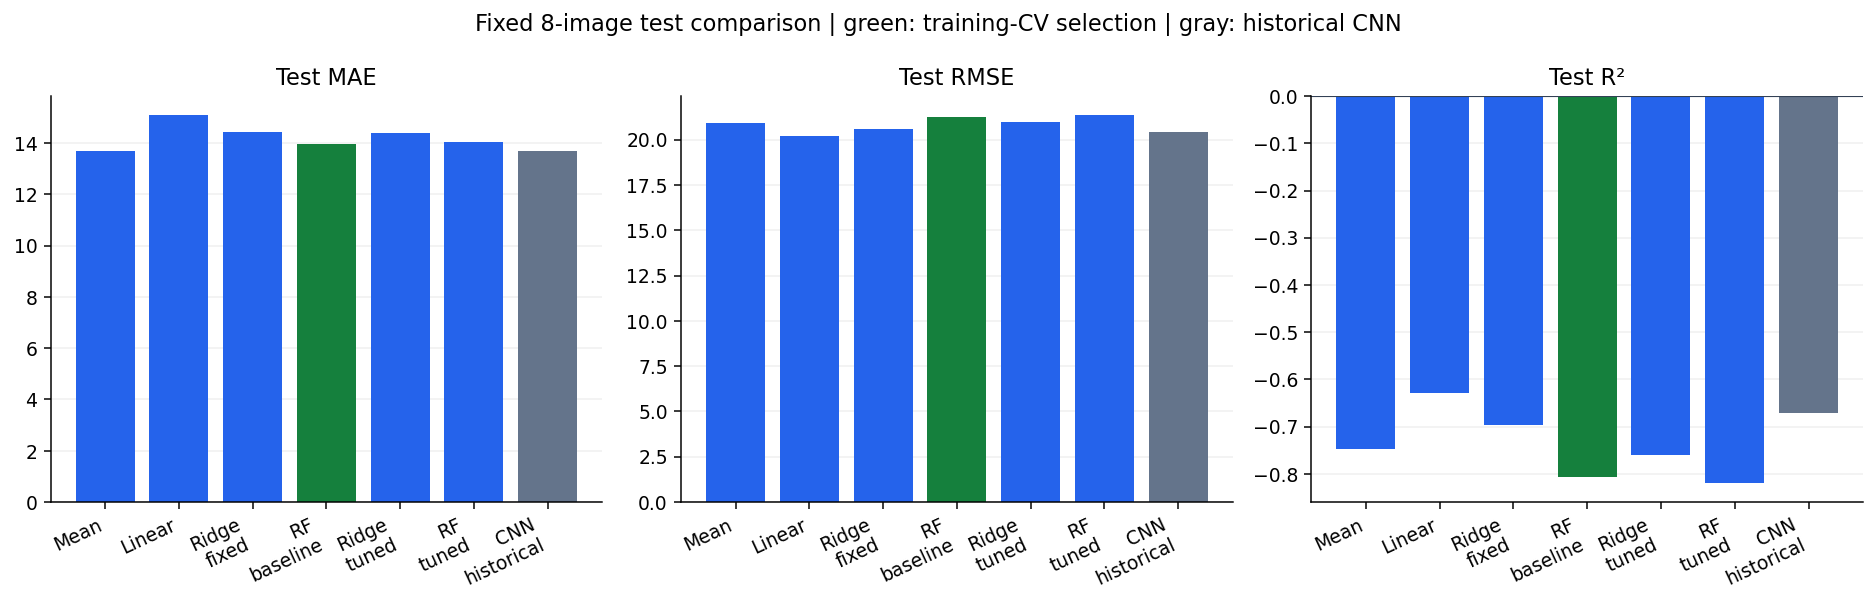

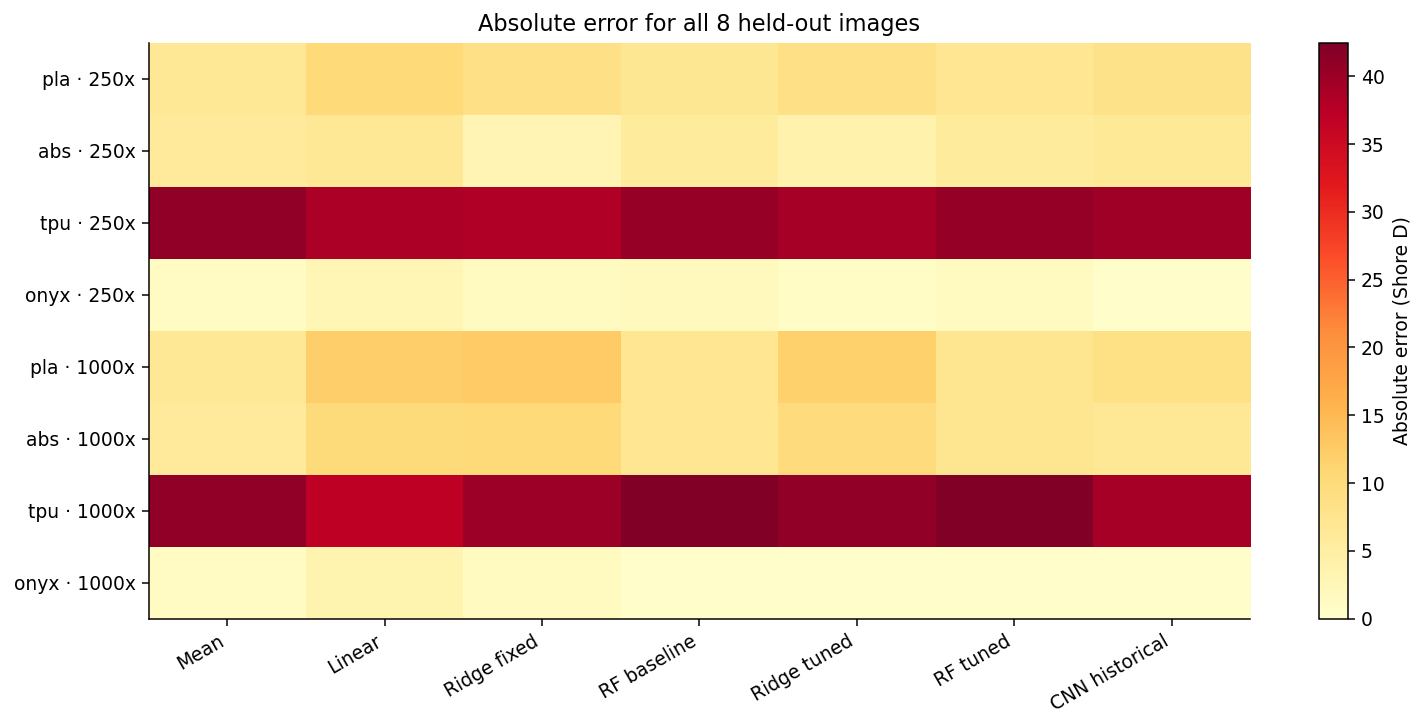

In [5]:
short_names = ['Mean', 'Linear', 'Ridge\nfixed', 'RF\nbaseline', 'Ridge\ntuned', 'RF\ntuned', 'CNN\nhistorical']
colors = ['#15803D' if n == selected_by_cv else '#64748B' if n == 'CNN historical' else '#2563EB'
          for n in test_metrics.index]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    ax.bar(range(len(test_metrics)), test_metrics[metric], color=colors)
    ax.set_xticks(range(len(test_metrics)), short_names, rotation=25, ha='right')
    ax.set_title('Test ' + ('R²' if metric == 'R2' else metric))
    ax.axhline(0, color='#334155', linewidth=.6)
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.suptitle('Fixed 8-image test comparison | green: training-CV selection | gray: historical CNN', fontsize=12)
fig.tight_layout()
fig.savefig(RESULT_DIR / 'notebook_test_metric_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

test_wide = test[['filename', 'hardness', 'magnification', 'material', 'condition_group']].copy()
error_rows = []
for name, prediction in test_predictions.items():
    assert np.isfinite(prediction).all()
    test_wide[name] = prediction
    for i, value in enumerate(prediction):
        error_rows.append({'model': name, 'filename': test['filename'].iloc[i],
                           'measured': float(y_test[i]), 'predicted': float(value),
                           'residual': float(value-y_test[i]), 'absolute_error': float(abs(value-y_test[i]))})
per_image_errors = pd.DataFrame(error_rows)
heat = per_image_errors.pivot(index='filename', columns='model', values='absolute_error').reindex(
    index=test['filename'], columns=list(test_predictions))
fig, ax = plt.subplots(figsize=(11.5, 5.5))
image = ax.imshow(heat.to_numpy(), aspect='auto', cmap='YlOrRd', vmin=0)
ax.set_xticks(range(7), [s.replace('\n', ' ') for s in short_names], rotation=30, ha='right')
ax.set_yticks(range(8), [n.replace('esd_', '').replace('.jpg', '').replace('_', ' · ') for n in heat.index])
ax.set_title('Absolute error for all 8 held-out images')
fig.colorbar(image, ax=ax, label='Absolute error (Shore D)')
fig.tight_layout()
fig.savefig(RESULT_DIR / 'notebook_per_image_absolute_error.png', dpi=180, bbox_inches='tight')
plt.show()


## 4. Main findings and interpretation

1. Baseline random forest minimizes training-CV MAE at 2.467 Shore D. Ridge tuning reduces CV MAE from 2.841 to 2.644, approximately 6.9%. Random-forest tuning increases CV MAE by approximately 2.8%.
2. Tuning gives no consistent fixed-test improvement. All test R² values are negative. Historical CNN test MAE is 13.672, compared with 13.675 for the training-mean predictor. Linear regression has the lowest test RMSE, so CNN does not lead every metric.
3. Training targets span 67.32–80.76 Shore D. Both TPU test views have a target of 35.26. Source study, composition and magnification change together, so this experiment cannot isolate a unique cause of the prediction errors.
4. Condition proxies do not establish physical-specimen independence. Eight images do not establish eight independent specimens or justify a statistical-significance claim.

These descriptive results do not establish reliable generalization across studies or prove that SEM images cannot predict hardness in a broader dataset.


In [6]:
cv_metrics.to_csv(RESULT_DIR / 'training_nested_group_cv_metrics.csv')
cv_folds.to_csv(RESULT_DIR / 'training_nested_group_cv_folds.csv', index=False)
oof = train[['filename', 'condition_group', 'hardness']].copy()
for name, prediction in cv_predictions.items(): oof[name] = prediction
oof.to_csv(RESULT_DIR / 'training_out_of_fold_predictions.csv', index=False)
test_metrics.to_csv(RESULT_DIR / 'final_test_metrics.csv')
test_wide.to_csv(RESULT_DIR / 'final_test_predictions.csv', index=False)
per_image_errors.to_csv(RESULT_DIR / 'per_image_errors.csv', index=False)
(RESULT_DIR / 'cv_fold_manifest.json').write_text(json.dumps(fold_manifest, indent=2), encoding='utf-8')
settings = {'input_sha256': FEATURE_CSV_SHA256, 'training_logic_sha256': TRAINING_LOGIC_SHA256,
            'seed': SEED, 'outer_folds': OUTER_FOLDS, 'inner_folds': INNER_FOLDS,
            'rf_search_candidates': RF_SEARCH_ITERATIONS,
            'group_definition': 'source + material + treatment + cycles; condition proxy, not verified specimen ID',
            'train_images': 76, 'test_images': 8, 'train_condition_groups': 28,
            'selected_by_training_cv_MAE': selected_by_cv, 'final_best_parameters': best_parameters,
            'new_CNN_training': False, 'image_features_recomputed_here': False,
            'test_scope': 'Previously viewed 8-image cross-study challenge; descriptive retrospective evaluation',
            'training_environment': {'python': platform.python_version(), 'numpy': np.__version__,
                                     'pandas': pd.__version__, 'sklearn': sklearn.__version__}}
(RESULT_DIR / 'experiment_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
zip_path = shutil.make_archive('MASC_520_Person3_Completed_Results', 'zip', RESULT_DIR)
print('Real computation completed. Relative output folder:', RESULT_DIR)
print('Result ZIP:', Path(zip_path).name)
print('No browser download API is needed. After rerunning in Colab, the ZIP is available in the left Files panel.')


Real computation completed. Relative output folder: person3_completed_results
Result ZIP: MASC_520_Person3_Completed_Results.zip
No browser download API is needed. After rerunning in Colab, the ZIP is available in the left Files panel.


## 5. Post-hoc diagnostics of the existing predictions

These checks explain the saved results. They do not fit new models or select new parameters.

- Both TPU views contribute approximately 93.27% of historical CNN squared error and 94.91% of baseline RF squared error. This identifies where the observed error is concentrated, rather than proving its unique cause.
- In the current direct-target standard random forest, every prediction is an average of training labels and therefore stays within 67.32–80.76. The most optimistic range-constrained predictions still give test R² no greater than approximately −0.02695. This is a mathematical ceiling for this RF setup, not an achieved score or a limit on Ridge or CNN.
- Both unseen test magnifications map to zero in the training-fitted categorical encoding. Their separate influence on error has not been isolated.
- Upstream source-image pairing, units and supplied raw-image hashes were not independently revalidated against all source images during this cached-feature run.

Recompute these checks from committed CSVs using `python scripts/check_results.py --check`. See `docs/DIAGNOSTICS.md` for definitions, numerical derivation and limitations.
